# EP02 — Simulação Discreta: Aplicativo de Transporte

**Grupo:** Gustavo Menegon Fais Pistozzo, Lucas Sacco Parisi e Vivian Carvalho Viana

Simulação do serviço de um aplicativo de transporte (caso 06) com Python e SimPy, para analisar a fila de solicitações e descobrir quantos motoristas são necessários para atender a demanda.

**Sumário**
1. Explicação do tema
2. Modelagem
3. Código da simulação
4. Experimentos
5. Conclusões

## 1. Explicação do tema

> TODO: colar aqui o texto do Passo 1: descrição do processo real, parâmetros com a origem de cada um, cenários, perguntas da análise e referências.

## 2. Modelagem

| Elemento do sistema de filas | No caso |
|---|---|
| Usuário | Passageiro que solicita uma corrida |
| Fila | Solicitações aguardando um motorista (FIFO) |
| Servidor | Motorista |
| Tempo de serviço | Deslocamento até o passageiro + duração da corrida |
| Eventos aleatórios | Recusa do motorista e desistência do passageiro |

Fluxo de um passageiro no modelo:

```
          chegada aleatória de solicitações
                        |
                        v
   +------------------------------------------+
   |  FILA DE SOLICITACOES (FIFO)             |---- espera > paciencia ----> DESISTENCIA
   |  [P5] [P4] [P3]                          |
   +------------------------------------------+
                        |  motorista livre
                        v
              +--------------------+
              |  motorista aceita? |---- nao (recusa) ----> volta para o fim da fila
              +--------------------+
                        |  sim
                        v
   +------------------------------------------+
   |  SERVICO = deslocamento  +  corrida      |     motoristas M1 ... Mn
   |            (Tempos mudam por cenário)    |
   +------------------------------------------+
                        |
                        v
           SAIDA (passageiro atendido)
           o motorista volta a ficar livre
```

> TODO: explicar com as palavras do grupo cada elemento e a variação obrigatória escolhida.

## 3. Código da simulação

Unidade de tempo de toda a simulação: **minutos**.

Ordem das células: instalação → bibliotecas → parâmetros → estruturas de métricas → sorteios → processos → simulação → gráficos → validação → resumo → variação → `main`.

In [58]:
# Instala o SimPy no Colab (o Colab já vem com numpy e matplotlib)
%pip install simpy -q

In [59]:
import math                                 # fatoriais da fórmula M/M/c (validação do modelo)
import random                               # sorteios das distribuições de probabilidade
from dataclasses import dataclass, field    # estruturas simples para guardar motoristas e métricas

import numpy as np                          # médias, percentis e vetores para os gráficos
import matplotlib.pyplot as plt             # os 5 gráficos de cada cenário
import simpy                                # simulação de eventos discretos (uso obrigatório)

### 3.1 Parâmetros dos cenários

In [60]:
SEMENTE = 42  # semente fixa: a mesma semente gera os mesmos sorteios, o que permite comparar cenários

CENARIOS = {
    "base": {
        "descricao": "Terça-feira, 14h, sem eventos, região do Allianz Parque",
        "intervalo_medio_chegada": 10,    # min (pesquisa: 1 solicitação a cada 10 min)
        "intervalo_medio_pico": None,     # Justificativa: sem pico neste cenário
        "pico_inicio": None,              # Justificativa: sem pico neste cenário
        "pico_fim": None,                 # Justificativa: sem pico neste cenário
        "deslocamento_medio": 5,          # min (pesquisa: observação própria)
        "deslocamento_desvio": 1.5,       # min (estimativa: ~95% dos deslocamentos entre 2 e 8 min)
        "corrida_min": 5,                 # min (estimativa)
        "corrida_moda": 10,               # min (estimativa)
        "corrida_max": 30,                # min (estimativa; média = (5+10+30)/3 = 15, como na pesquisa)
        "num_motoristas": 3,              # motoristas perto do estádio num dia comum (estimativa)
        "paciencia_intervalo": 10,        # min (pesquisa: a cada 10 min de espera...)
        "prob_desistir": 0.30,            # (pesquisa: ...30% de chance de desistir)
        "prob_recusa": 0.10,              # pesquisa: 10% de cancelamento pelo motorista
        "tempo_simulado": 180,            # min (pesquisa: 3 horas)
    },
    "volume": {
        "descricao": "Terça-feira, 20h30, horário de pico, sem eventos",
        "intervalo_medio_chegada": 7,     # min (pesquisa: 1 solicitação a cada 7 min)
        "intervalo_medio_pico": None,     # Justificativa: sem pico neste cenário
        "pico_inicio": None,              # Justificativa: sem pico neste cenário
        "pico_fim": None,                 # Justificativa: sem pico neste cenário
        "deslocamento_medio": 5,          # min (pesquisa)
        "deslocamento_desvio": 1.5,
        "corrida_min": 8,                 # min (estimativa)
        "corrida_moda": 12,               # min (estimativa)
        "corrida_max": 40,                # min (estimativa; média = (8+12+40)/3 = 20, como na pesquisa)
        "num_motoristas": 4,              # um motorista a mais que no base (estimativa)
        "paciencia_intervalo": 10,
        "prob_desistir": 0.30,
        "prob_recusa": 0.10,
        "tempo_simulado": 180,
    },
    "extremo": {
        "descricao": "Sábado, saída de um show no Allianz Parque",   # TODO: 18h30 ou 20h30? (a pesquisa usa os dois)
        "intervalo_medio_chegada": 7,     # min fora do pico (estimativa: igual ao volume)
        "intervalo_medio_pico": 0.4,      # min no pico (pesquisa: 5 solicitações a cada 2 min)
        "pico_inicio": 30,                # min: o show termina 30 min após o início da simulação
        "pico_fim": 90,                   # min: 1 hora de saída do público (estimativa)
        "deslocamento_medio": 12,         # min (pesquisa: trânsito no entorno do show)
        "deslocamento_desvio": 3,         # min (estimativa: ~95% entre 6 e 18 min)
        "corrida_min": 20,                # min (estimativa)
        "corrida_moda": 30,               # min (estimativa)
        "corrida_max": 70,                # min (estimativa; média = (20+30+70)/3 = 40, como na pesquisa)
        "num_motoristas": 100,            # pesquisa: 100 motoristas ao redor do Allianz Parque
        "paciencia_intervalo": 10,
        "prob_desistir": 0.30,
        "prob_recusa": 0.10,
        "tempo_simulado": 180,
    },
}

TESTE_MMC = {
    "intervalo_medio_chegada": 3,     # λ = 1/3 por min
    "intervalo_medio_pico": None,     # Justificativa: sem pico neste cenário
    "pico_inicio": None,              # Justificativa: sem pico neste cenário
    "pico_fim": None,                 # Justificativa: sem pico neste cenário
    "servico_exponencial": True,      # serviço = uma exponencial...
    "servico_medio": 20,              # ...com média 20 min → μ = 1/20 por min
    "num_motoristas": 8,              # c = 8
    "paciencia_intervalo": 10**9,     # ninguém desiste
    "prob_desistir": 1.0,
    "prob_recusa": 0.0,               # ninguém recusa
    "tempo_simulado": 50000,          # longo, para a média estabilizar
}

### 3.2 Estruturas para guardar as métricas

In [61]:
@dataclass
class Motorista:
    # Um servidor do sistema. Cada motorista é um objeto separado para medir o trabalho de cada um (gráfico 4).
    id: int
    tempo_ocupado: float = 0.0                          # soma dos minutos em atendimento
    atendimentos: list = field(default_factory=list)    # (inicio, fim) de cada atendimento
    recusas: int = 0                                    # quantas corridas este motorista recusou


@dataclass
class Metricas:
    # Tudo o que a simulação registra para os gráficos e para o resumo de um cenário.

    # Amostras ao longo do tempo, preenchidas pelo processo monitor (gráficos 1 e 2)
    tempos_amostra: list = field(default_factory=list)      # instantes t das amostras
    tamanho_fila: list = field(default_factory=list)        # solicitações esperando no instante t
    usuarios_sistema: list = field(default_factory=list)    # esperando + em corrida no instante t

    # Um registro por passageiro atendido (gráfico 3): (t_chegada, tempo_na_fila, tempo_no_sistema)
    atendidos: list = field(default_factory=list)

    # Instante de cada desistência (gráfico 5)
    instantes_desistencia: list = field(default_factory=list)

    # Lista de objetos Motorista do cenário (gráfico 4)
    motoristas: list = field(default_factory=list)

    # Contadores para o resumo
    total_solicitacoes: int = 0
    total_recusas: int = 0

### 3.3 Sorteio dos tempos aleatórios

O enunciado pede, para cada cenário, a distribuição escolhida, os valores dos parâmetros e por que ela representa o tema. Cada sorteio fica numa função própria para trocar a distribuição num lugar só.

In [62]:
def sortear_intervalo_chegada(cen, agora):
    # Minutos até a próxima solicitação.
    media = cen["intervalo_medio_chegada"]
    if cen["pico_inicio"] is not None and cen["pico_inicio"] <= agora < cen["pico_fim"]:
        media = cen["intervalo_medio_pico"]
    return random.expovariate(1 / media)

def sortear_deslocamento(cen):
    # Minutos do motorista até o passageiro (primeira parte do tempo de serviço).
    return max(1, random.gauss(cen["deslocamento_medio"], cen["deslocamento_desvio"]))

def sortear_corrida(cen):
    # Minutos da corrida em si (segunda parte do tempo de serviço).
    return random.triangular(cen["corrida_min"], cen["corrida_max"], cen["corrida_moda"])

def sortear_paciencia(cen):
    # Minutos que o passageiro aceita esperar antes de cancelar (desistência).
    paciencia = cen["paciencia_intervalo"]
    while random.random() >= cen["prob_desistir"]:
        paciencia += cen["paciencia_intervalo"]
    return paciencia

def sortear_servico(cen):
    # Tempo total de serviço. No teste de validação, uma única exponencial (exigência da fórmula M/M/c).
    if cen.get("servico_exponencial"):
        return random.expovariate(1 / cen["servico_medio"])
    return sortear_deslocamento(cen) + sortear_corrida(cen)

### 3.4 Processos da simulação

Os motoristas livres ficam num `simpy.Store`. Pedir um motorista é `motoristas.get()` e liberá-lo é `motoristas.put(m)`. O `Store` foi escolhido em vez do `simpy.Resource` porque com `Resource` não dá para saber qual motorista atendeu, e o gráfico 4 pede o trabalho de cada um.

In [63]:
def passageiro(env, pid, motoristas, cen, met):
    # Vida de um passageiro, da solicitação até a saída (atendido ou desistente).

    # Guardando dados:
    t_chegada = env.now
    paciencia = sortear_paciencia(cen)

    while True:
        paciencia_restante = paciencia - (env.now - t_chegada)

        # Pedir um motorista e esperar o que vier primeiro, o motorista ou o fim da paciência:
        pedido = motoristas.get()
        resultado = yield pedido | env.timeout(paciencia_restante)

        # DESISTÊNCIA: a paciência acabou antes:
        if pedido not in resultado:
            pedido.cancel()
            met.instantes_desistencia.append(env.now)
            return

        # RECUSA: chances do motorista recusar
        m = pedido.value
        if random.random() < cen["prob_recusa"]:
            m.recusas += 1
            met.total_recusas += 1
            yield motoristas.put(m)
            continue
        break

    # ACEITOU
    tempo_na_fila = env.now - t_chegada

    # SERVIÇO
    inicio = env.now
    yield env.timeout(sortear_servico(cen))
    m.atendimentos.append((inicio, env.now))
    m.tempo_ocupado += env.now - inicio

    # SAÍDA
    yield motoristas.put(m)
    met.atendidos.append((t_chegada, tempo_na_fila, env.now - t_chegada))


def gerador_solicitacoes(env, motoristas, cen, met):
    # Cria um passageiro novo a cada intervalo sorteado, enquanto a simulação roda.
    # Roda para sempre
    while True:
        yield env.timeout(sortear_intervalo_chegada(cen, env.now))
        met.total_solicitacoes += 1
        env.process(passageiro(env, met.total_solicitacoes, motoristas, cen, met))


def monitor(env, motoristas, cen, met, intervalo=1):
    # Tira uma "foto" do sistema a cada `intervalo` minutos (dados dos gráficos 1 e 2).
    while True:
        fila = len(motoristas.get_queue)                          # pedidos esperando motorista
        ocupados = cen["num_motoristas"] - len(motoristas.items)  # motoristas fora do Store
        met.tempos_amostra.append(env.now)
        met.tamanho_fila.append(fila)
        met.usuarios_sistema.append(fila + ocupados)
        yield env.timeout(intervalo)

In [64]:
def simular(cen, semente=SEMENTE):
    # Roda um cenário do começo ao fim e devolve as Metricas.
    random.seed(semente)
    env = simpy.Environment()
    lista = [Motorista(i) for i in range(cen["num_motoristas"])]
    motoristas = simpy.Store(env)
    motoristas.items.extend(lista)
    met = Metricas(motoristas=lista)
    env.process(gerador_solicitacoes(env, motoristas, cen, met))
    env.process(monitor(env, motoristas, cen, met))
    env.run(until=cen["tempo_simulado"])
    return met

### 3.5 Gráficos

Os 5 gráficos que o enunciado pede para cada cenário. Uma função por gráfico, reaproveitada em todos os cenários.

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estilo visual consistente
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   '#F8FAFB',
    'axes.grid':        True,
    'grid.alpha':       0.4,
    'font.family':      'DejaVu Sans',
    "axes.titlesize": 12,
    "axes.labelsize": 10.5,
})

TEAL = '#007A7A'
GOLD = '#E6A817'
DARK = '#0D1B2A'

print("Tudo ok.")


Tudo ok.


In [102]:
def marcar_pico(cen):
  # Ajuda os gráficos 1, 2, 3 e 5: pinta de leve o intervalo do pico (só no cenário extremo).
  if cen["pico_inicio"] is not None:
    plt.axvspan(
        cen["pico_inicio"],
        cen["pico_fim"],
        color=GOLD,
        alpha=0.15,
        label="pico (fim do show)",
    )

In [103]:
def plot_fila(met, cen, titulo, altura=4.0):
  print("\n1. Tamanho da fila")
  print(
      "Mostra quantas solicitações ficaram na fila a cada minuto"
      " (amostragem de 1 em 1 min)."
  )
  plt.figure(figsize=(10, altura))
  plt.step(
      met.tempos_amostra,
      met.tamanho_fila,
      where="post",
      color=TEAL,
      linewidth=2,
      label="tamanho da fila",
  )
  marcar_pico(cen)
  plt.title(titulo, color=DARK, fontweight="bold")
  plt.xlabel("Tempo (min)", color=DARK)
  plt.ylabel("Solicitações na fila", color=DARK)
  plt.legend()
  plt.tight_layout()
  plt.show()
  plt.close()

  pass


In [104]:
def plot_usuarios_sistema(met, cen, titulo, altura=4.0):
  print("\n2. Passageiros no sistema")
  print(
      "Mostra o total de passageiros (na fila + em corrida) comparado ao"
      " limite de motoristas."
  )
  plt.figure(figsize=(10, altura))
  plt.step(
      met.tempos_amostra,
      met.usuarios_sistema,
      where="post",
      color=TEAL,
      linewidth=2,
      label="no sistema",
  )
  plt.axhline(
      cen["num_motoristas"],
      color=DARK,
      linestyle="--",
      linewidth=1.5,
      label="limite de motoristas",
  )
  marcar_pico(cen)
  plt.title(titulo, color=DARK, fontweight="bold")
  plt.xlabel("Tempo (min)", color=DARK)
  plt.ylabel("Passageiros no sistema", color=DARK)
  plt.legend()
  plt.tight_layout()
  plt.show()
  plt.close()

In [105]:
def plot_tempos(met, cen, titulo, altura=4.0):
  print("\n3. Tempo na fila e no sistema")
  print(
      "Mostra o tempo na fila e o tempo total no sistema para cada passageiro"
      " atendido."
  )
  plt.figure(figsize=(10, altura))
  if not met.atendidos:
    plt.text(
        0.5,
        0.5,
        "nenhum passageiro atendido nesta rodada",
        ha="center",
        va="center",
        color=DARK,
        fontsize=12,
    )
    plt.title(titulo, color=DARK, fontweight="bold")
    plt.tight_layout()
    plt.show()
    plt.close()
    return

  x = [a[0] for a in met.atendidos]
  fila = [a[1] for a in met.atendidos]
  sistema = [a[2] for a in met.atendidos]

  plt.scatter(x, fila, color=TEAL, alpha=0.65, label="tempo na fila")
  plt.scatter(x, sistema, color=GOLD, alpha=0.65, label="tempo no sistema")

  media_fila = np.mean(fila)
  media_sistema = np.mean(sistema)
  plt.axhline(
      media_fila,
      color=TEAL,
      linestyle="--",
      alpha=0.8,
      label=f"média fila ({media_fila:.1f} min)",
  )
  plt.axhline(
      media_sistema,
      color=GOLD,
      linestyle="--",
      alpha=0.8,
      label=f"média sistema ({media_sistema:.1f} min)",
  )

  marcar_pico(cen)
  plt.title(titulo, color=DARK, fontweight="bold")
  plt.xlabel("Instante da solicitação (min)", color=DARK)
  plt.ylabel("Tempo (min)", color=DARK)
  plt.legend()
  plt.tight_layout()
  plt.show()
  plt.close()

In [106]:
def plot_trabalho_motoristas(met, cen, titulo, altura=4.8):
  print("\n4. Trabalho dos motoristas")
  print(
      "Mostra os intervalos de tempo em que cada motorista ficou ocupado em"
      " corridas."
  )
  plt.figure(figsize=(10, altura))
  motoristas = met.motoristas
  titulo_ajustado = titulo

  if len(motoristas) > 20:
    motoristas = motoristas[:20]
    titulo_ajustado += " (20 primeiros motoristas)"

  for m in motoristas:
    barras = [(ini, fim - ini) for ini, fim in m.atendimentos]
    plt.broken_barh(
        barras,
        (m.id - 0.4, 0.8),
        facecolors=TEAL,
        edgecolors=DARK,
        linewidth=0.5,
    )

  plt.title(titulo_ajustado, color=DARK, fontweight="bold")
  plt.xlabel("Tempo (min)", color=DARK)
  plt.ylabel("ID do motorista", color=DARK)
  plt.tight_layout()
  plt.show()
  plt.close()

In [107]:
def plot_desistencias(met, cen, titulo, altura=4.0):
  print("\n5. Desistências acumuladas")
  print(
      "Mostra o total acumulado de desistências ao longo do tempo (quando a"
      " espera passa da paciência)."
  )
  plt.figure(figsize=(10, altura))
  if not met.instantes_desistencia:
    plt.text(
        0.5,
        0.5,
        "nenhuma desistência nesta rodada",
        ha="center",
        va="center",
        color=DARK,
        fontsize=12,
    )
    plt.title(titulo, color=DARK, fontweight="bold")
    plt.tight_layout()
    plt.show()
    plt.close()
    return

  x = sorted(met.instantes_desistencia)
  y = list(range(1, len(x) + 1))

  plt.step(
      x,
      y,
      where="post",
      color=DARK,
      linewidth=2,
      marker="o",
      label="desistências acumuladas",
  )
  marcar_pico(cen)
  plt.title(titulo, color=DARK, fontweight="bold")
  plt.xlabel("Tempo (min)", color=DARK)
  plt.ylabel("Total de desistências", color=DARK)
  plt.legend()
  plt.tight_layout()
  plt.show()
  plt.close()

In [108]:
def plotar_cenario(
    met, nome, alt_fila=4.0, alt_sist=4.0, alt_tempos=4.0, alt_trab=4.8, alt_des=4.0
):
  cen = CENARIOS[nome]
  titulo = f"{nome}: {cen['descricao']} (rodada semente {SEMENTE})"
  print("\n" + "=" * 70)
  print(titulo)
  print("=" * 70)
  plot_fila(met, cen, titulo, altura=alt_fila)
  plot_usuarios_sistema(met, cen, titulo, altura=alt_sist)
  plot_tempos(met, cen, titulo, altura=alt_tempos)
  plot_trabalho_motoristas(met, cen, titulo, altura=alt_trab)
  plot_desistencias(met, cen, titulo, altura=alt_des)

In [109]:
def plot_variacao_motoristas(resultados_por_cenario):
    # Gráfico do Passo 3: espera e desistência conforme o número de motoristas (média de 30 rodadas).
    cenarios = list(resultados_por_cenario.keys())
    fig, axes = plt.subplots(1, len(cenarios), figsize=(5.5 * len(cenarios), 4.5))

    if len(cenarios) == 1:
        axes = [axes]

    for ax, nome in zip(axes, cenarios):
        resultados = resultados_por_cenario[nome]
        x = [r["motoristas"] for r in resultados]
        espera = [r["espera"] for r in resultados]
        desistencia = [r["desistencia_pct"] for r in resultados]

        ax.plot(x, espera, color=TEAL, marker="o", linewidth=2, label="espera média (min)")
        ax.plot(x, desistencia, color=GOLD, marker="s", linewidth=2, label="desistência (%)")

        atual = CENARIOS[nome]["num_motoristas"]
        ax.axvline(atual, color=DARK, linestyle="--", alpha=0.7, label=f"atual ({atual})")

        ax.set_title(nome, color=DARK, fontweight='bold')
        ax.set_xlabel("número de motoristas", color=DARK)
        ax.legend()

    plt.tight_layout()
    plt.show()

    pass

In [110]:
def rodar_cenario(nome, semente=SEMENTE):
  cen = CENARIOS[nome]
  met = simular(cen, semente=semente)
  resumo(met, nome)
  plotar_cenario(met, nome)
  return met

### 3.6 Validação do modelo

Antes de confiar nos resultados: rodar um caso simples (sem desistência, sem recusa, tempos exponenciais) e comparar a espera média simulada com a fórmula da fila M/M/c. Se os números ficarem próximos, o código está montando a fila corretamente.

In [111]:


def espera_media_mmc(lam, mu, c):
    # Espera média na fila (Wq) de uma fila M/M/c, pela fórmula de Erlang C.
    a = lam / mu
    rho = a / c
    if rho >= 1:
        raise ValueError("rho precisa ser menor que 1: com essa demanda a fila cresce sem parar")

    termo_c = a**c / (math.factorial(c) * (1 - rho))
    P0 = 1 / (sum(a**k / math.factorial(k) for k in range(c)) + termo_c)
    C = termo_c * P0
    Wq = C / (c * mu - lam)
    return Wq

def validar_modelo():
    # Compara a espera média simulada com a fórmula M/M/c (Erlang C).
    # Usa o TESTE_MMC (3.1): serviço exponencial, ninguém desiste, ninguém recusa.
    met = simular(TESTE_MMC)
    esperas = [a[1] for a in met.atendidos]
    espera_simulada = np.mean(esperas)

    lam = 1 / TESTE_MMC["intervalo_medio_chegada"]
    mu = 1 / TESTE_MMC["servico_medio"]
    c = TESTE_MMC["num_motoristas"]
    espera_formula = espera_media_mmc(lam, mu, c)

    diferenca = abs(espera_simulada - espera_formula) / espera_formula * 100

    print("Validação do modelo (M/M/c)")
    print(f"  Espera média simulada: {espera_simulada:.2f} min ({len(esperas)} passageiros)")
    print(f"  Espera pela fórmula:   {espera_formula:.2f} min")
    print(f"  Diferença:             {diferenca:.1f}%")


def resumo(met, nome):
    # Imprime as respostas às perguntas da análise para um cenário.
    cen = CENARIOS[nome]
    na_fila = [a[1] for a in met.atendidos]
    no_sistema = [a[2] for a in met.atendidos]

    atendidos = len(met.atendidos)
    desistencias = len(met.instantes_desistencia)
    no_fim = met.total_solicitacoes - atendidos - desistencias

    espera_fila = np.mean(na_fila) if na_fila else 0
    tempo_sistema = np.mean(no_sistema) if no_sistema else 0

    ocupacao_media = sum(m.tempo_ocupado for m in met.motoristas) / (cen["num_motoristas"] * cen["tempo_simulado"]) * 100

    print(f"=== {nome}: {cen['descricao']} ===")
    print(f"Solicitações:            {met.total_solicitacoes}")
    print(f"Atendidos:               {atendidos}")
    print(f"Desistências:            {desistencias}")
    print(f"Ainda no sistema no fim: {no_fim}")
    print(f"Recusas:                 {met.total_recusas}")
    print(f"Espera média na fila:    {espera_fila:.1f} min")
    print(f"Tempo médio no sistema:  {tempo_sistema:.1f} min")
    print(f"Ocupação média dos motoristas: {ocupacao_media:.1f}%")

    if cen["pico_inicio"] is not None:
        na_fila_pico = [a[1] for a in met.atendidos if cen["pico_inicio"] <= a[0] < cen["pico_fim"]]
        espera_pico = np.mean(na_fila_pico) if na_fila_pico else 0
        print(f"Espera média na fila durante o pico: {espera_pico:.1f} min ({len(na_fila_pico)} passageiros)")

### 3.7 Variação do número de motoristas

In [112]:
def variar_motoristas(nome, lista_de_quantidades, replicacoes=30):
    # Roda um cenário com várias quantidades de motoristas e compara os resultados.
    # Responde a pergunta da análise: "quantos motoristas são necessários?"
    # Cada quantidade roda `replicacoes` vezes com sementes diferentes, e o resultado é a média.
    cen_original = CENARIOS[nome]
    resultados = []

    for n in lista_de_quantidades:
        cen = {**cen_original, "num_motoristas": n}
        esperas = []
        desistencias_pct = []
        ocupacoes = []

        for semente in range(1, replicacoes + 1):
            met = simular(cen, semente)

            # Espera na fila; no cenário com pico, só de quem chegou durante o pico
            if cen["pico_inicio"] is not None:
                na_fila = [a[1] for a in met.atendidos if cen["pico_inicio"] <= a[0] < cen["pico_fim"]]
            else:
                na_fila = [a[1] for a in met.atendidos]

            espera = np.mean(na_fila) if na_fila else 0
            desistencia = len(met.instantes_desistencia) / met.total_solicitacoes * 100
            ocupacao = sum(m.tempo_ocupado for m in met.motoristas) / (n * cen["tempo_simulado"]) * 100

            esperas.append(espera)
            desistencias_pct.append(desistencia)
            ocupacoes.append(ocupacao)

        # Média das replicações: uma linha da tabela para este n
        espera_media = np.mean(esperas)
        desistencia_media = np.mean(desistencias_pct)
        ocupacao_media = np.mean(ocupacoes)

        resultados.append({"motoristas": n, "espera": espera_media,
                           "desistencia_pct": desistencia_media, "ocupacao": ocupacao_media})
        print(f"{n:>5} motoristas | espera {espera_media:5.1f} min | "
              f"desistência {desistencia_media:5.1f}% | ocupação {ocupacao_media:5.1f}%")

    return resultados

### 3.8 Função principal

In [113]:
def main():
    # Ordem de execução do notebook.
    validar_modelo()

    for nome, cen in CENARIOS.items():
        met = simular(cen)
        resumo(met, nome)
        # plotar_cenario(met, nome) <-- Vivian

    # Passo 3
    QUANTIDADES = {
        "base": [2, 3, 4, 5, 6],
        "volume": [3, 4, 5, 6, 7],
        "extremo": [60, 80, 100, 120, 140],
    }
    resultados_por_cenario = {}
    for nome, lista in QUANTIDADES.items():
        print(f"\n=== {nome}: variando o número de motoristas ===")
        resultados_por_cenario[nome] = variar_motoristas(nome, lista)

    return resultados_por_cenario

if __name__ == "__main__":
    resultados_por_cenario = main()

Validação do modelo (M/M/c)
  Espera média simulada: 7.70 min (16524 passageiros)
  Espera pela fórmula:   7.99 min
  Diferença:             3.7%
=== base: Terça-feira, 14h, sem eventos, região do Allianz Parque ===
Solicitações:            20
Atendidos:               18
Desistências:            1
Ainda no sistema no fim: 1
Recusas:                 1
Espera média na fila:    3.1 min
Tempo médio no sistema:  22.8 min
Ocupação média dos motoristas: 65.4%
=== volume: Terça-feira, 20h30, horário de pico, sem eventos ===
Solicitações:            19
Atendidos:               16
Desistências:            2
Ainda no sistema no fim: 1
Recusas:                 3
Espera média na fila:    1.5 min
Tempo médio no sistema:  28.8 min
Ocupação média dos motoristas: 60.7%
=== extremo: Sábado, saída de um show no Allianz Parque ===
Solicitações:            124
Atendidos:               119
Desistências:            0
Ainda no sistema no fim: 5
Recusas:                 16
Espera média na fila:    0.0 min
Temp

## 4. Experimentos

> TODO (Passo 3): para cada cenário (base, volume, extremo), explicar as 5 configurações (distribuição da chegada, distribuição do serviço, desistências, tempo simulado e número de motoristas), mostrar os 5 gráficos e comentar.


base: Terça-feira, 14h, sem eventos, região do Allianz Parque (rodada semente 42)

1. Tamanho da fila
Mostra quantas solicitações ficaram na fila a cada minuto (amostragem de 1 em 1 min).


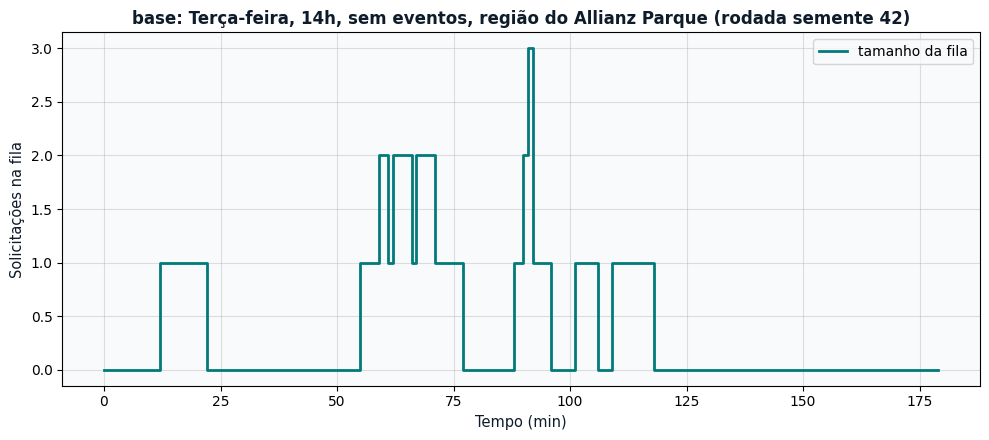


2. Passageiros no sistema
Mostra o total de passageiros (na fila + em corrida) comparado ao limite de motoristas.


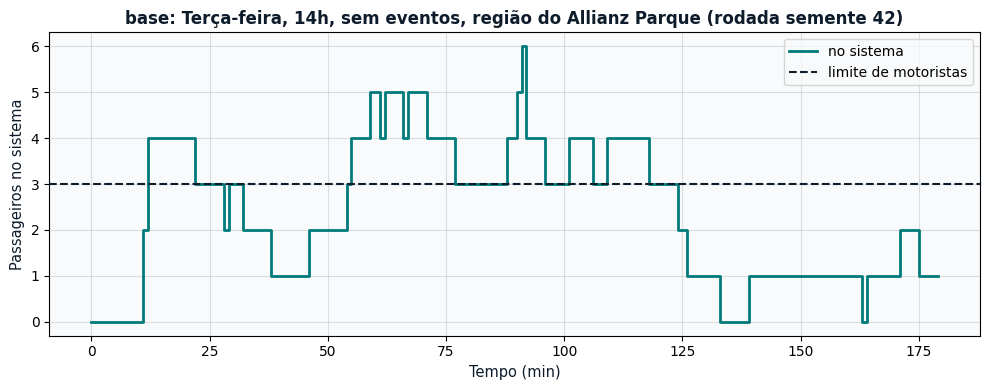


3. Tempo na fila e no sistema
Mostra o tempo na fila e o tempo total no sistema para cada passageiro atendido.


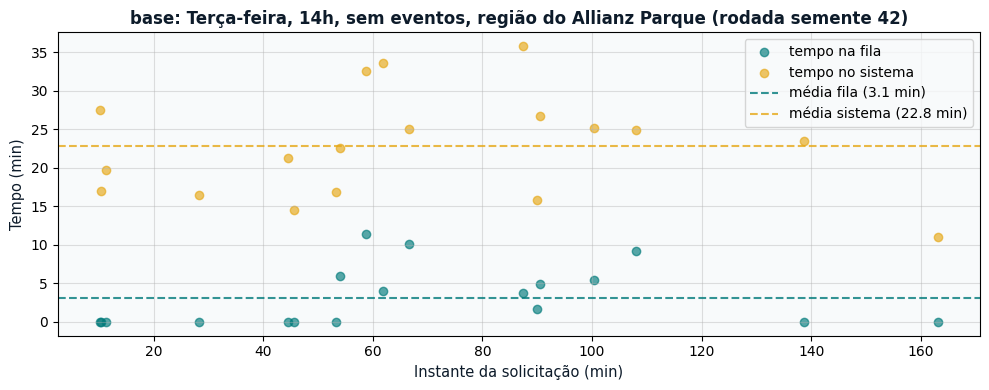


4. Trabalho dos motoristas
Mostra os intervalos de tempo em que cada motorista ficou ocupado em corridas.


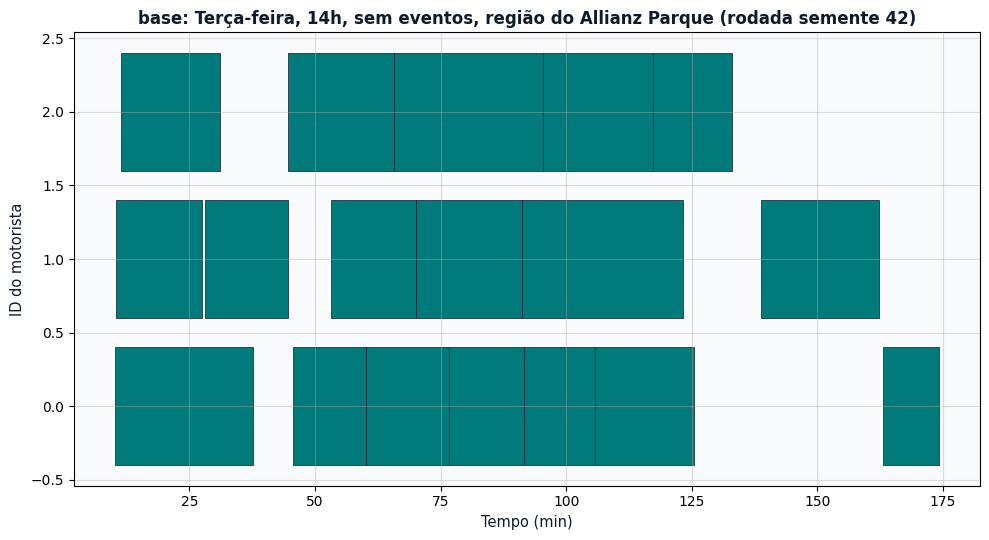


5. Desistências acumuladas
Mostra o total acumulado de desistências ao longo do tempo (quando a espera passa da paciência).


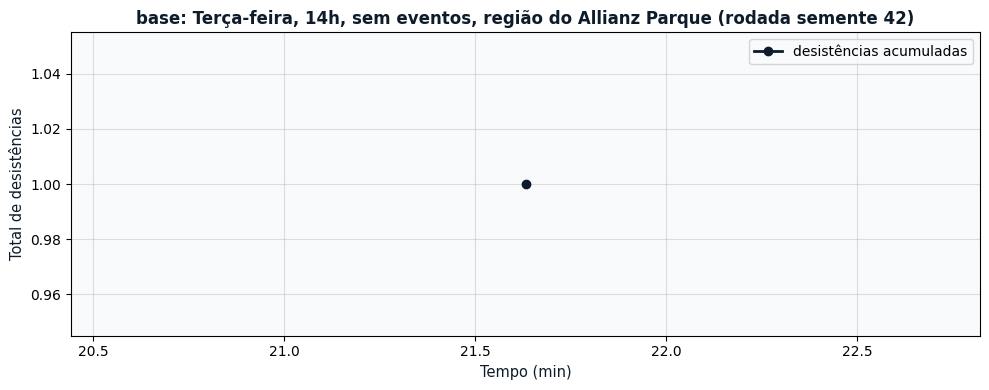

In [114]:
plotar_cenario(met_base, "base", alt_fila=4.5, alt_trab=5.5)

=== volume: Terça-feira, 20h30, horário de pico, sem eventos ===
Solicitações:            19
Atendidos:               16
Desistências:            2
Ainda no sistema no fim: 1
Recusas:                 3
Espera média na fila:    1.5 min
Tempo médio no sistema:  28.8 min
Ocupação média dos motoristas: 60.7%

volume: Terça-feira, 20h30, horário de pico, sem eventos (rodada semente 42)

1. Tamanho da fila
Mostra quantas solicitações ficaram na fila a cada minuto (amostragem de 1 em 1 min).


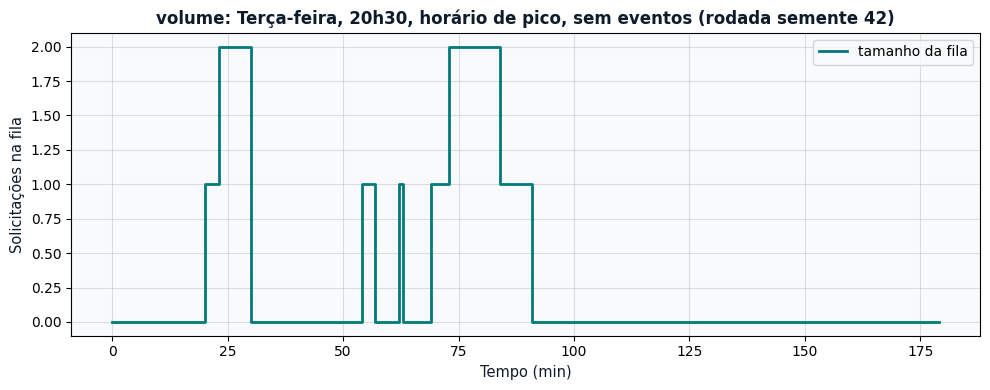


2. Passageiros no sistema
Mostra o total de passageiros (na fila + em corrida) comparado ao limite de motoristas.


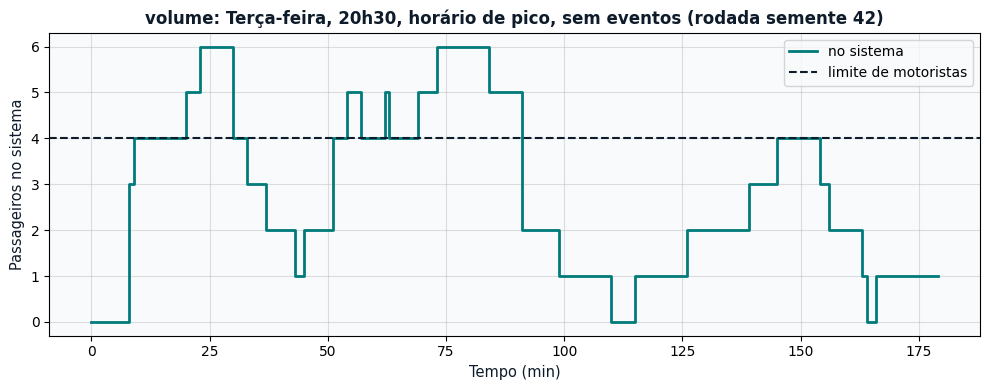


3. Tempo na fila e no sistema
Mostra o tempo na fila e o tempo total no sistema para cada passageiro atendido.


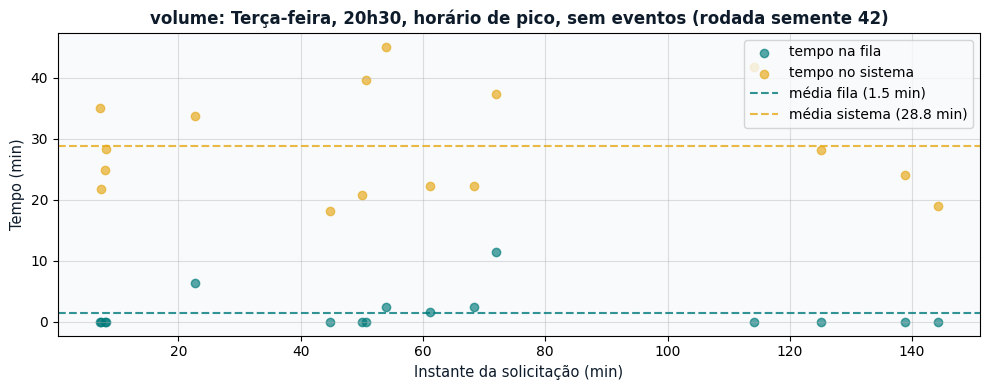


4. Trabalho dos motoristas
Mostra os intervalos de tempo em que cada motorista ficou ocupado em corridas.


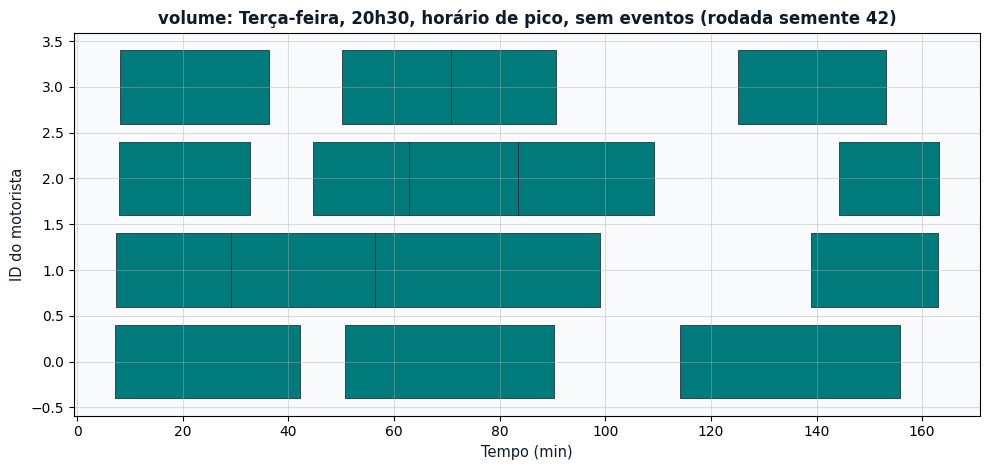


5. Desistências acumuladas
Mostra o total acumulado de desistências ao longo do tempo (quando a espera passa da paciência).


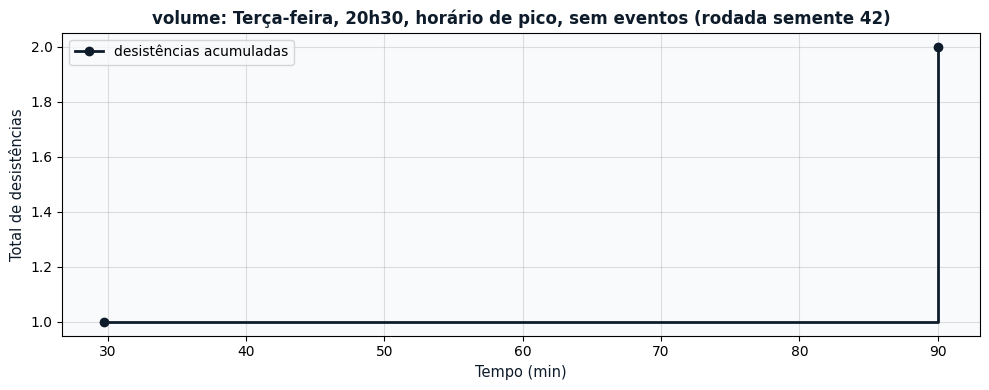

In [115]:
met_volume = rodar_cenario("volume")

=== extremo: Sábado, saída de um show no Allianz Parque ===
Solicitações:            124
Atendidos:               119
Desistências:            0
Ainda no sistema no fim: 5
Recusas:                 16
Espera média na fila:    0.0 min
Tempo médio no sistema:  52.4 min
Ocupação média dos motoristas: 34.7%
Espera média na fila durante o pico: 0.0 min (110 passageiros)

extremo: Sábado, saída de um show no Allianz Parque (rodada semente 42)

1. Tamanho da fila
Mostra quantas solicitações ficaram na fila a cada minuto (amostragem de 1 em 1 min).


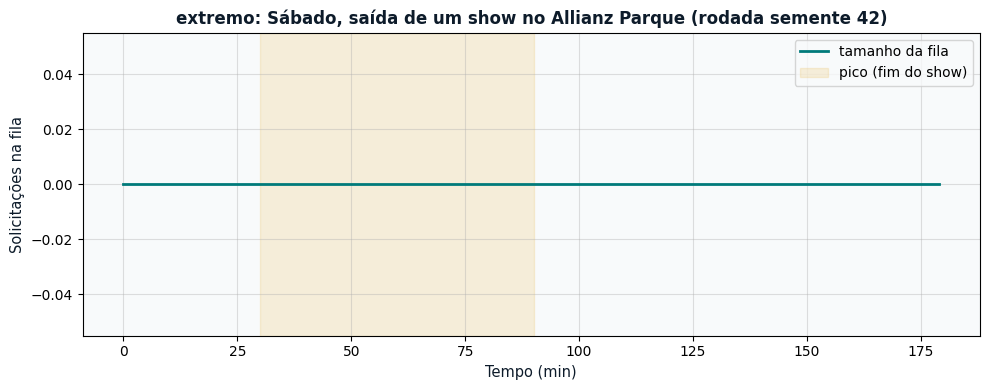


2. Passageiros no sistema
Mostra o total de passageiros (na fila + em corrida) comparado ao limite de motoristas.


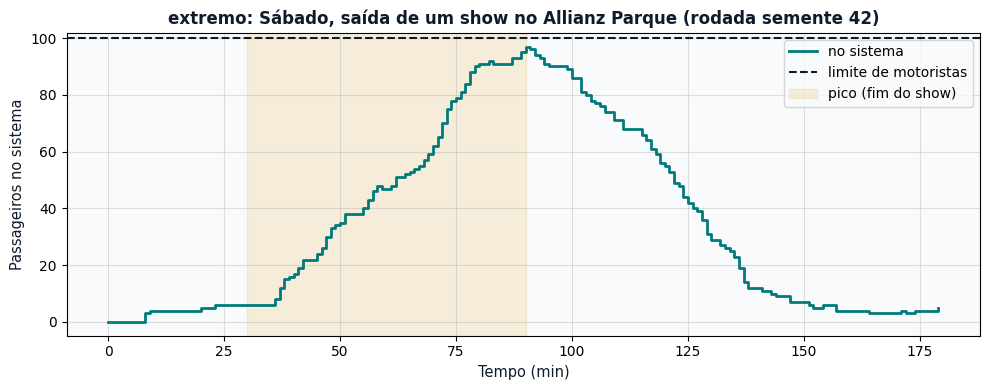


3. Tempo na fila e no sistema
Mostra o tempo na fila e o tempo total no sistema para cada passageiro atendido.


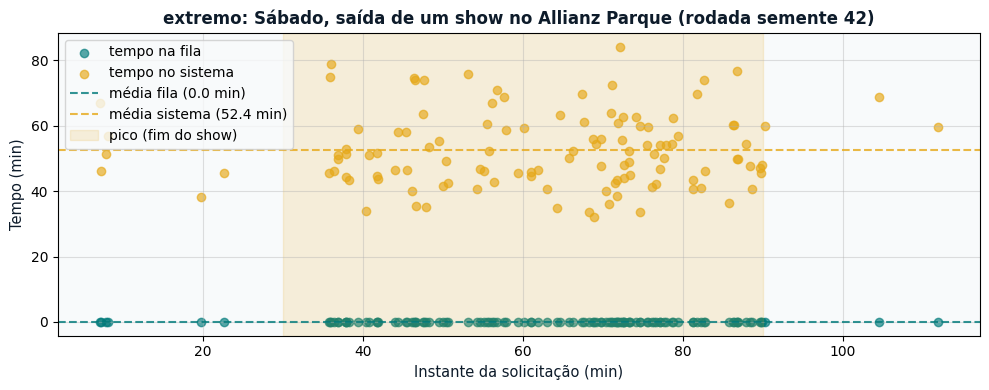


4. Trabalho dos motoristas
Mostra os intervalos de tempo em que cada motorista ficou ocupado em corridas.


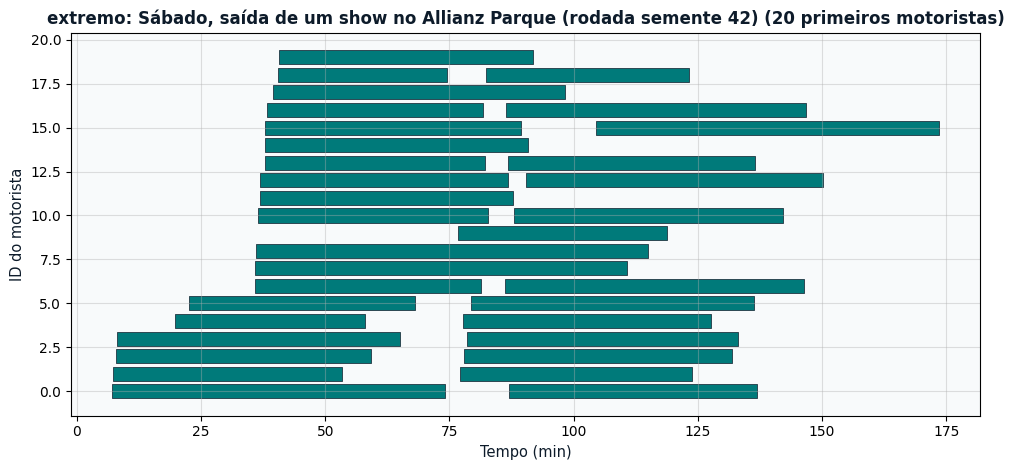


5. Desistências acumuladas
Mostra o total acumulado de desistências ao longo do tempo (quando a espera passa da paciência).


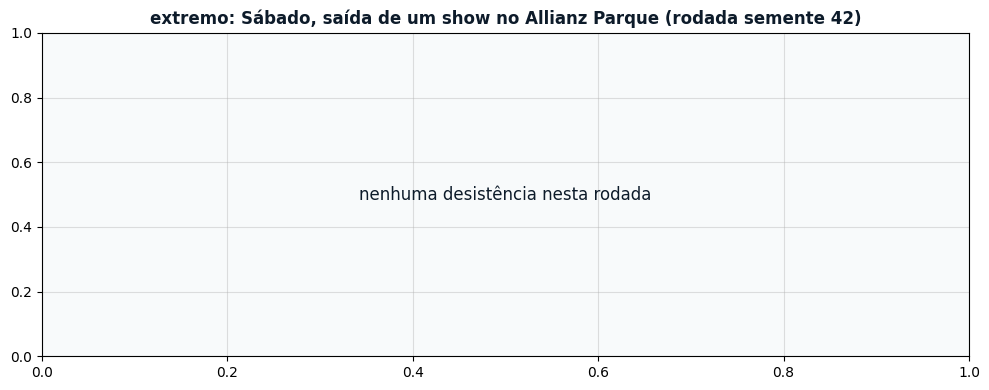

In [116]:
met_extremo = rodar_cenario("extremo")

## 5. Conclusões

> TODO: responder as perguntas da análise e dizer qual seria a configuração ideal de motoristas para cada cenário.